## CyberPulse — Network Traffic Forecasting


In [1]:
import pandas as pd

df = pd.read_csv(
    "https://raw.githubusercontent.com/uSebaa/CyberPulse-Forecasting/main/network_flows.csv"
)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (9770, 38)

Columns:
['flow_id', 'session_id', 'source_ip_hash', 'destination_ip_hash', 'source_port', 'dest_port', 'protocol', 'flow_start_timestamp', 'flow_duration_ms', 'total_fwd_packets', 'total_bwd_packets', 'total_bytes_fwd', 'total_bytes_bwd', 'fwd_packet_len_mean', 'fwd_packet_len_std', 'bwd_packet_len_mean', 'bwd_packet_len_std', 'flow_bytes_per_sec', 'flow_packets_per_sec', 'inter_arrival_time_mean', 'inter_arrival_time_std', 'tcp_flag_syn_count', 'tcp_flag_ack_count', 'tcp_flag_fin_count', 'tcp_flag_rst_count', 'tcp_flag_psh_count', 'tcp_flag_urg_count', 'flow_lifecycle_phase', 'traffic_category', 'attack_subcategory', 'label', 'segment_id', 'source_device_type', 'dest_device_type', 'attacker_capability_tier', 'retransmission_flag', 'fragmentation_flag', 'protocol_violation_flag']


In [ ]:
# Convert timestamps to datetime
df["flow_start_timestamp"] = pd.to_datetime(
    df["flow_start_timestamp"],
    errors="coerce"
)

# Count network flows per hour
hourly_flows = (
    df.dropna(subset=["flow_start_timestamp"])
      .set_index("flow_start_timestamp")
      .resample("h")
      .size()
      .rename("n_flows")
      .to_frame()
)

print("Time series shape:", hourly_flows.shape)
print("Start:", hourly_flows.index.min())
print("End:", hourly_flows.index.max())
print("Missing values:", hourly_flows["n_flows"].isna().sum())
print("Zero-flow hours:", (hourly_flows["n_flows"] == 0).sum())

display(hourly_flows.head())

Time series shape: (719, 1)
Start: 2024-01-01 01:00:00
End: 2024-01-30 23:00:00
Missing values: 0
Zero-flow hours: 177


,n_flows
flow_start_timestamp,
2024-01-01 01:00:00,4
2024-01-01 02:00:00,55
2024-01-01 03:00:00,5
2024-01-01 04:00:00,20
2024-01-01 05:00:00,0


## A — Exploration


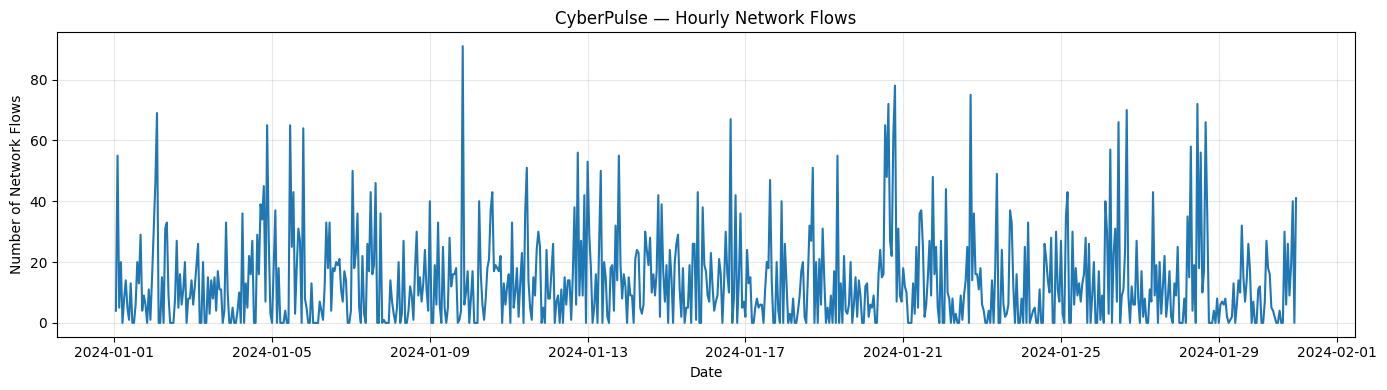

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 4))

plt.plot(
    hourly_flows.index,
    hourly_flows["n_flows"]
)

plt.title("CyberPulse — Hourly Network Flows")
plt.xlabel("Date")
plt.ylabel("Number of Network Flows")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

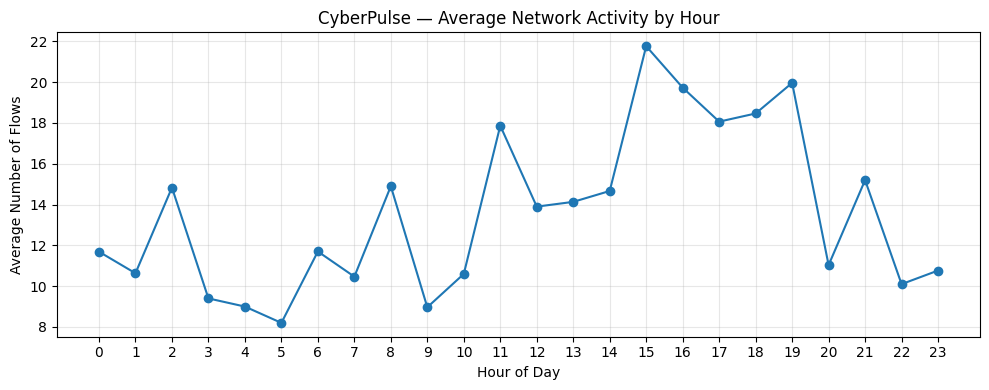

In [ ]:
# Average network flows by hour of day
hourly_pattern = hourly_flows.groupby(
    hourly_flows.index.hour
)["n_flows"].mean()

plt.figure(figsize=(10, 4))
plt.plot(hourly_pattern.index, hourly_pattern.values, marker="o")

plt.title("CyberPulse — Average Network Activity by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Number of Flows")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

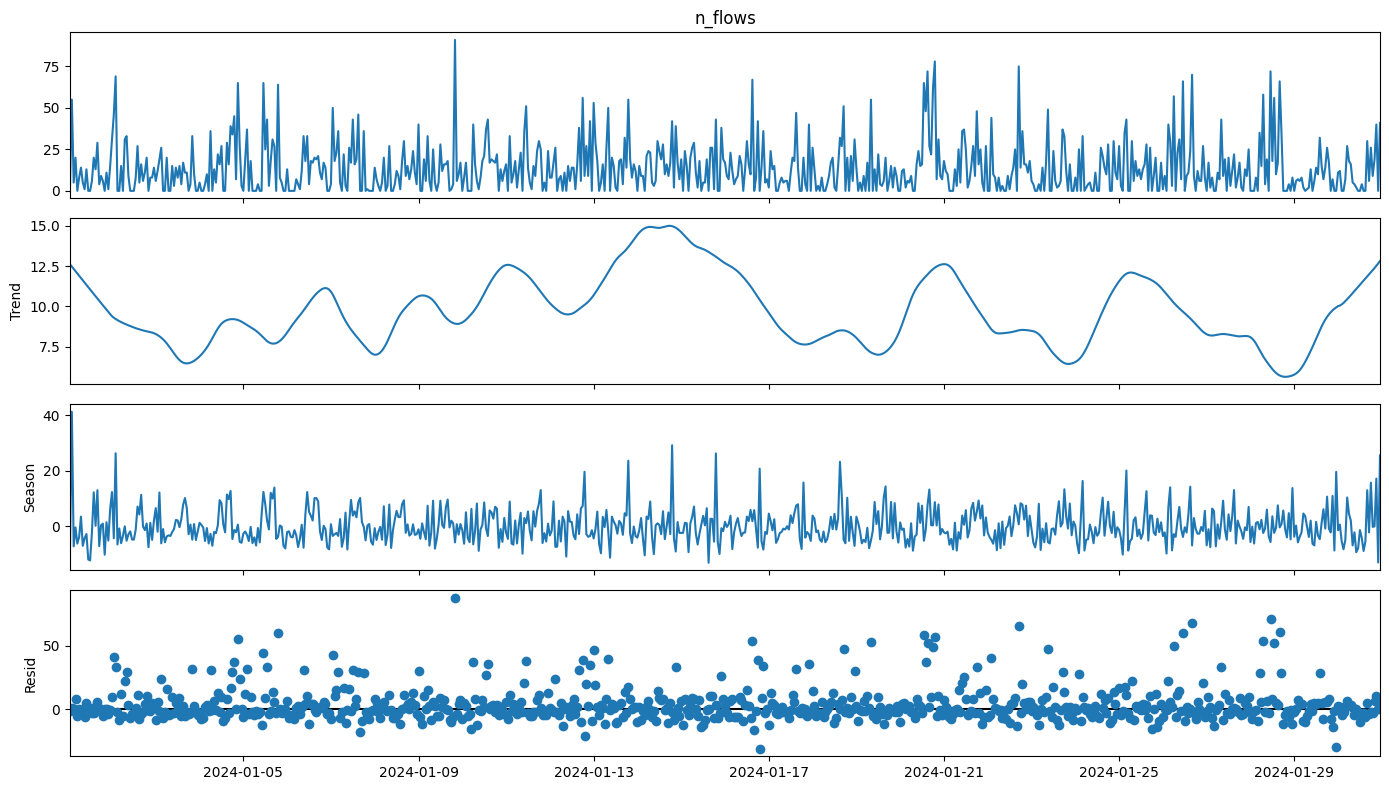

In [ ]:
from statsmodels.tsa.seasonal import STL
import matplotlib.pyplot as plt

# Decompose hourly network activity
stl = STL(
    hourly_flows["n_flows"],
    period=24,
    robust=True
)

result = stl.fit()

fig = result.plot()
fig.set_size_inches(14, 8)
plt.tight_layout()
plt.show()

In [ ]:
from statsmodels.tsa.seasonal import STL
import numpy as np

stl_result = STL(hourly_flows["n_flows"], period=24).fit()

trend_strength = max(
    0, 1 - np.var(stl_result.resid) /
    np.var(stl_result.trend + stl_result.resid)
)

seasonal_strength = max(
    0, 1 - np.var(stl_result.resid) /
    np.var(stl_result.seasonal + stl_result.resid)
)

print(f"Trend Strength: {trend_strength:.3f}")
print(f"Seasonal Strength: {seasonal_strength:.3f}")

Trend Strength: 0.094
Seasonal Strength: 0.363


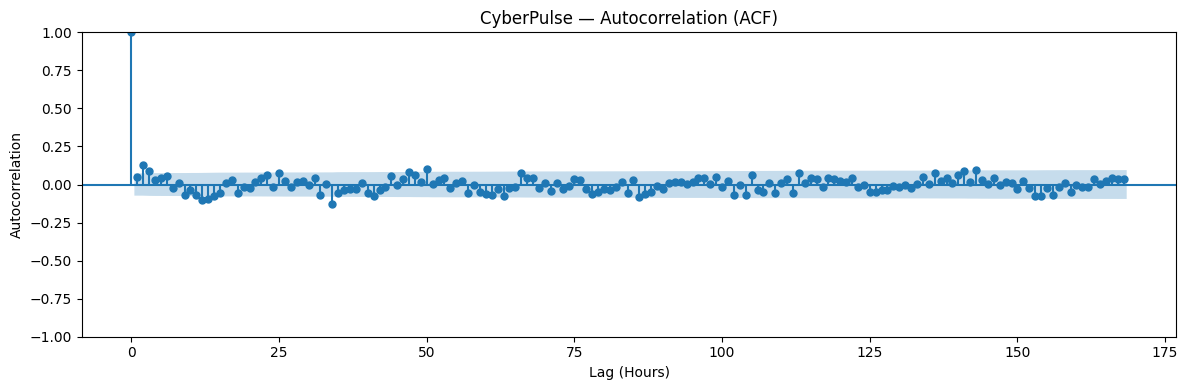

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plot_acf(
    hourly_flows["n_flows"],
    lags=168,
    alpha=0.05,
    ax=plt.gca()
)

plt.title("CyberPulse — Autocorrelation (ACF)")
plt.xlabel("Lag (Hours)")
plt.ylabel("Autocorrelation")
plt.tight_layout()
plt.show()

## B — Baselines


In [ ]:
# Forecasting configuration
FREQ = "h"
SEASON_LENGTH = 24
H = 24

# Chronological train/test split
train = hourly_flows.iloc[:-H].copy()
test = hourly_flows.iloc[-H:].copy()

print("Training observations:", len(train))
print("Testing observations:", len(test))
print("Forecast horizon:", H, "hours")
print("Season length:", SEASON_LENGTH, "hours")

Training observations: 695
Testing observations: 24
Forecast horizon: 24 hours
Season length: 24 hours


In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error

# Seasonal Naive Baseline
seasonal_naive_pred = train["n_flows"].iloc[-SEASON_LENGTH:].to_numpy()

# Actual values
y_test = test["n_flows"].to_numpy()

# Evaluate predictions
seasonal_naive_mae = mean_absolute_error(
    y_test,
    seasonal_naive_pred
)

print("Seasonal Naive MAE:", round(seasonal_naive_mae, 2))

Seasonal Naive MAE: 12.83


In [ ]:
# Naive Baseline: Repeat the last observed value
naive_pred = np.repeat(
    train["n_flows"].iloc[-1],
    H
)

# Evaluate Naive Baseline
naive_mae = mean_absolute_error(
    y_test,
    naive_pred
)

# Compare baseline models
baseline_results = pd.DataFrame({
    "Model": ["Naive", "Seasonal Naive"],
    "MAE": [naive_mae, seasonal_naive_mae]
})

display(baseline_results.round(2))

,Model,MAE
0,Naive,11.54
1,Seasonal Naive,12.83


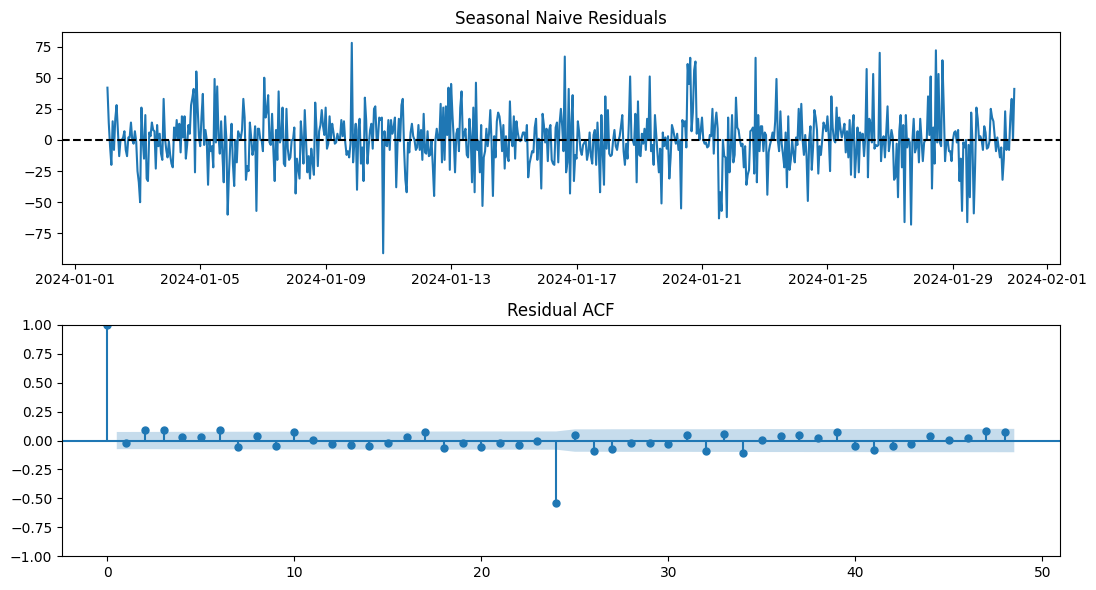

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

# Seasonal Naive residuals
residuals = (
    hourly_flows["n_flows"]
    - hourly_flows["n_flows"].shift(24)
).dropna()

fig, axes = plt.subplots(2, 1, figsize=(11, 6))

axes[0].plot(residuals)
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set_title("Seasonal Naive Residuals")

plot_acf(residuals, lags=48, ax=axes[1])
axes[1].set_title("Residual ACF")

plt.tight_layout()
plt.show()

The Seasonal Naive residuals fluctuate around zero with several large spikes. Most ACF values are weak, but a strong negative correlation appears at lag 24. This suggests that the seasonal baseline does not fully capture the hourly traffic patterns.

In [ ]:
# Seasonal Naive 80% prediction interval from training-only seasonal errors
train_values = train["n_flows"].to_numpy()
seasonal_errors = train_values[SEASON_LENGTH:] - train_values[:-SEASON_LENGTH]
seasonal_lower = seasonal_naive_pred + np.quantile(seasonal_errors, 0.1)
seasonal_upper = seasonal_naive_pred + np.quantile(seasonal_errors, 0.9)
seasonal_coverage = np.mean((y_test >= seasonal_lower) & (y_test <= seasonal_upper))
print(f"Seasonal Naive 80% interval coverage: {seasonal_coverage:.1%}")


## C — AutoGluon


In [ ]:
%pip install -q autogluon.timeseries

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 2.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 274.4/274.4 kB 13.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.7/90.7 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 248.4/248.4 kB 18.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 112.3/112.3 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 514.8/514.8 kB 31.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.8/80.8 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 285.4/285.4 kB 22.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 281.0/281.0 kB 21.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 864.0/864.0 kB 38.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 43.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
from autogluon.timeseries import TimeSeriesDataFrame

# Prepare the hourly time series
ag_df = hourly_flows.reset_index()

# Rename columns for AutoGluon
ag_df = ag_df.rename(columns={
    "flow_start_timestamp": "timestamp",
    "n_flows": "target"
})

# Add an item ID (we have one network time series)
ag_df["item_id"] = "CyberPulse_Network"

# Convert to AutoGluon format
ag_data = TimeSeriesDataFrame.from_data_frame(
    ag_df,
    id_column="item_id",
    timestamp_column="timestamp"
)

print("AutoGluon data shape:", ag_data.shape)
display(ag_data.head())

AutoGluon data shape: (719, 1)


target
item_id            timestamp                  
CyberPulse_Network 2024-01-01 01:00:00       4
                   2024-01-01 02:00:00      55
                   2024-01-01 03:00:00       5
                   2024-01-01 04:00:00      20
                   2024-01-01 05:00:00       0

In [ ]:
from autogluon.timeseries import TimeSeriesPredictor

# Keep the last 24 hours for testing
ag_train = ag_data.slice_by_timestep(None, -H)

# Configure the forecasting model
predictor = TimeSeriesPredictor(
    target="target",
    prediction_length=H,
    freq="h",
    eval_metric="MASE",
    path="CyberPulse_AutoGluon"
)

# Train forecasting models
predictor.fit(
    train_data=ag_train,
    presets="fast_training",
    time_limit=180,
    random_seed=42
)

Preset 'fast_training' is deprecated and will be removed in a future release. Falling back to 'medium_quality'.
Beginning AutoGluon training... Time limit = 180s
AutoGluon will save models to '/content/CyberPulse_AutoGluon'
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.13.16
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #1 SMP Thu Apr 30 18:17:14 UTC 2026
CPU Count:          2
Pytorch Version:    2.11.0+cpu
CUDA Version:       CUDA is not available
GPU Memory:         
Total GPU Memory:   Free: 0.00 GB, Allocated: 0.00 GB, Total: 0.00 GB
GPU Count:          0
Memory Avail:       11.36 GB / 12.67 GB (89.6%)
Disk Space Avail:   86.34 GB / 107.72 GB (80.2%)
Setting presets to: medium_quality

Fitting with arguments:
{'enable_ensemble': True,
 'eval_metric': MASE,
 'freq': 'h',
 'hyperparameters': 'light',
 'known_covariates_names': [],
 'num_val_windows': 1,
 'prediction_length': 24,
 'quantile_levels': [0.1,

config.json:   0%|          | 0.00/969 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  112MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/92 [00:00<?, ?it/s]

	-0.3458       = Validation score (-MASE)
	17.43   s     = Training runtime
	1.26    s     = Validation (prediction) runtime
Training timeseries model Toto2. Training for up to 72.3s of the 144.6s of remaining time.


config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 16.6MB            

model.safetensors: downloading bytes:           |  0.00B            

	-0.3913       = Validation score (-MASE)
	1.44    s     = Training runtime
	0.12    s     = Validation (prediction) runtime
Fitting 1 ensemble(s), in 1 layers.
Training ensemble model WeightedEnsemble. Training for up to 143.0s.
	Ensemble weights: {'Chronos2': 1.0}
	-0.3458       = Validation score (-MASE)
	0.55    s     = Training runtime
	1.26    s     = Validation (prediction) runtime
Training complete. Models trained: ['SeasonalNaive', 'RecursiveTabular', 'DirectTabular', 'ETS', 'Theta', 'Chronos2', 'Toto2', 'WeightedEnsemble']
Total runtime: 33.75 s
Best model: Chronos2
Best model score: -0.3458


In [ ]:
# AutoGluon leaderboard on held-out test data
test_leaderboard = predictor.leaderboard(
    ag_data,
    display=False
)

display(test_leaderboard)

Additional data provided, testing on additional data. Resulting leaderboard will be sorted according to test score (`score_test`).


Loading weights:   0%|          | 0/92 [00:00<?, ?it/s]

,model,score_test,score_val,pred_time_test,pred_time_val,fit_time_marginal,fit_order
0,Theta,-0.612511,-0.587030,0.042705,0.043190,0.015672,5
1,WeightedEnsemble,-0.701822,-0.345808,0.683070,1.263819,0.546672,8
2,Chronos2,-0.701822,-0.345808,0.682106,1.262987,17.427132,6
3,DirectTabular,-0.717291,-0.520393,0.092043,0.089640,0.777834,3
4,Toto2,-0.727939,-0.391349,0.334398,0.123320,1.438394,7
5,RecursiveTabular,-0.740759,-0.572455,0.165787,0.321175,2.505191,2
6,ETS,-0.748326,-0.553902,0.167642,2.074296,0.016755,4
7,SeasonalNaive,-0.812758,-1.085215,0.009475,0.019272,0.034659,1


AutoGluon evaluated eight models using one internal validation window. The negative scores represent MASE with its sign reversed, so values closer to zero are better. Theta performed best on the held-out 24 hours, while Chronos2 was selected using internal validation. A single holdout is not enough to establish consistent superiority; rolling backtesting provides stronger evidence.

In [ ]:
# Forecast the next 24 hours using Chronos2
ag_predictions = predictor.predict(
    ag_train,
    model="Chronos2"
)

# Extract point forecasts
chronos_pred = ag_predictions["mean"].to_numpy()

# Evaluate on the held-out test period
chronos_mae = mean_absolute_error(
    y_test,
    chronos_pred
)

# Compare with our baselines
test_results = pd.DataFrame({
    "Model": ["Naive", "Seasonal Naive", "Chronos2"],
    "Test MAE": [
        naive_mae,
        seasonal_naive_mae,
        chronos_mae
    ]
}).sort_values("Test MAE")

display(test_results.round(2))

Loading weights:   0%|          | 0/92 [00:00<?, ?it/s]

,Model,Test MAE
2,Chronos2,11.08
0,Naive,11.54
1,Seasonal Naive,12.83


## D — Rolling-Origin Backtesting


In [ ]:
# Rolling Backtesting Configuration
N_WINDOWS = 5
STEP_SIZE = 24

# Define chronological backtesting windows
backtest_windows = []

for i in range(N_WINDOWS, 0, -1):
    test_end = len(hourly_flows) - (i - 1) * STEP_SIZE
    test_start = test_end - H

    backtest_windows.append({
        "Window": N_WINDOWS - i + 1,
        "Train End": hourly_flows.index[test_start - 1],
        "Test Start": hourly_flows.index[test_start],
        "Test End": hourly_flows.index[test_end - 1]
    })

backtest_schedule = pd.DataFrame(backtest_windows)

display(backtest_schedule)

,Window,Train End,Test Start,Test End
0,1,2024-01-25 23:00:00,2024-01-26,2024-01-26 23:00:00
1,2,2024-01-26 23:00:00,2024-01-27,2024-01-27 23:00:00
2,3,2024-01-27 23:00:00,2024-01-28,2024-01-28 23:00:00
3,4,2024-01-28 23:00:00,2024-01-29,2024-01-29 23:00:00
4,5,2024-01-29 23:00:00,2024-01-30,2024-01-30 23:00:00


In [ ]:
# Rolling Backtesting — Baseline Models

backtest_results = []

for i in range(N_WINDOWS, 0, -1):

    test_end = len(hourly_flows) - (i - 1) * STEP_SIZE
    test_start = test_end - H

    # Use only historical data
    history = hourly_flows["n_flows"].iloc[:test_start].to_numpy()

    # Actual future values
    actual = hourly_flows["n_flows"].iloc[test_start:test_end].to_numpy()

    # Naive forecast
    naive_forecast = np.repeat(history[-1], H)

    # Seasonal Naive forecast
    seasonal_forecast = history[-SEASON_LENGTH:]

    # Evaluate both models
    for model_name, forecast in [
        ("Naive", naive_forecast),
        ("Seasonal Naive", seasonal_forecast)
    ]:
        mae = mean_absolute_error(actual, forecast)

        # MASE scaling based on training history only
        scale = np.mean(
            np.abs(
                history[SEASON_LENGTH:] -
                history[:-SEASON_LENGTH]
            )
        )

        mase = mae / scale if scale > 0 else np.nan

        backtest_results.append({
            "Window": N_WINDOWS - i + 1,
            "Model": model_name,
            "MAE": mae,
            "MASE": mase
        })

baseline_backtest = pd.DataFrame(backtest_results)

display(baseline_backtest.round(3))

,Window,Model,MAE,MASE
0,1,Naive,16.208,1.045
1,1,Seasonal Naive,16.292,1.051
2,2,Naive,7.708,0.496
3,2,Seasonal Naive,17.583,1.132
4,3,Naive,21.625,1.385
5,3,Seasonal Naive,19.000,1.217
6,4,Naive,6.375,0.405
7,4,Seasonal Naive,17.083,1.085
8,5,Naive,11.542,0.731
9,5,Seasonal Naive,12.833,0.813


In [ ]:
# Rolling Backtesting — Chronos2
chronos_results = []

for i in range(N_WINDOWS, 0, -1):
    test_end = len(ag_data) - (i - 1) * STEP_SIZE
    test_start = test_end - H

    history = ag_data.slice_by_timestep(None, test_start)
    actual = hourly_flows["n_flows"].iloc[test_start:test_end].to_numpy()

    # Fresh Chronos2 predictor for this window
    bt_predictor = TimeSeriesPredictor(
        target="target",
        prediction_length=H,
        freq="h",
        eval_metric="MASE",
        path=f"CyberPulse_BT_{N_WINDOWS-i+1}"
    )

    bt_predictor.fit(
        train_data=history,
        hyperparameters={"Chronos2": {}},
        skip_model_selection=True,
        time_limit=120
    )

    forecast = bt_predictor.predict(history)
    predicted = forecast["mean"].to_numpy()

    history_values = hourly_flows["n_flows"].iloc[:test_start].to_numpy()
    scale = np.mean(
        np.abs(
            history_values[SEASON_LENGTH:] -
            history_values[:-SEASON_LENGTH]
        )
    )

    chronos_results.append({
        "Window": N_WINDOWS - i + 1,
        "Model": "Chronos2",
        "MAE": mean_absolute_error(actual, predicted),
        "MASE": mean_absolute_error(actual, predicted) / scale
    })

chronos_backtest = pd.DataFrame(chronos_results)

# Compare all models
all_backtest = pd.concat(
    [baseline_backtest, chronos_backtest],
    ignore_index=True
)

display(
    all_backtest.groupby("Model")[["MAE", "MASE"]]
    .mean()
    .round(3)
)

Beginning AutoGluon training... Time limit = 120s
AutoGluon will save models to '/content/CyberPulse_BT_1'
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.13.16
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #1 SMP Thu Apr 30 18:17:14 UTC 2026
CPU Count:          2
Pytorch Version:    2.11.0+cpu
CUDA Version:       CUDA is not available
GPU Memory:         
Total GPU Memory:   Free: 0.00 GB, Allocated: 0.00 GB, Total: 0.00 GB
GPU Count:          0
Memory Avail:       10.96 GB / 12.67 GB (86.5%)
Disk Space Avail:   86.16 GB / 107.72 GB (80.0%)

Fitting with arguments:
{'enable_ensemble': True,
 'eval_metric': MASE,
 'freq': 'h',
 'hyperparameters': {'Chronos2': {}},
 'known_covariates_names': [],
 'num_val_windows': 1,
 'prediction_length': 24,
 'quantile_levels': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
 'random_seed': 123,
 'refit_every_n_windows': 1,
 'refit_full': False,
 'skip_model_selection': True

config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  478MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

...

Beginning AutoGluon training... Time limit = 120s
AutoGluon will save models to '/content/CyberPulse_BT_5'
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.13.16
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #1 SMP Thu Apr 30 18:17:14 UTC 2026
CPU Count:          2
Pytorch Version:    2.11.0+cpu
CUDA Version:       CUDA is not available
GPU Memory:         
Total GPU Memory:   Free: 0.00 GB, Allocated: 0.00 GB, Total: 0.00 GB
GPU Count:          0
Memory Avail:       10.93 GB / 12.67 GB (86.3%)
Disk Space Avail:   85.72 GB / 107.72 GB (79.6%)

Fitting with arguments:
{'enable_ensemble': True,
 'eval_metric': MASE,
 'freq': 'h',
 'hyperparameters': {'Chronos2': {}},
 'known_covariates_names': [],
 'num_val_windows': 1,
 'prediction_length': 24,
 'quantile_levels': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
 'random_seed': 123,
 'refit_every_n_windows': 1,
 'refit_full': False,
 'skip_model_selection': True

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

	0.69    s     = Training runtime
Training complete. Models trained: ['Chronos2']
Total runtime: 0.71 s
Best model: Chronos2
Model not specified in predict, will default to the model with the best validation score: Chronos2


Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

,MAE,MASE
Model,,
Chronos2,11.196,0.717
Naive,12.692,0.812
Seasonal Naive,16.558,1.059


In [ ]:
# Probabilistic Backtesting — Chronos2

from scipy.stats import norm

prob_results = []

for window in range(1, N_WINDOWS + 1):

    test_end = len(ag_data) - (N_WINDOWS - window) * STEP_SIZE
    test_start = test_end - H

    history = ag_data.slice_by_timestep(None, test_start)
    actual = hourly_flows["n_flows"].iloc[test_start:test_end].to_numpy()

    bt_predictor = TimeSeriesPredictor.load(
        f"CyberPulse_BT_{window}"
    )

    forecast = bt_predictor.predict(history)

    lower = forecast["0.1"].to_numpy()
    upper = forecast["0.9"].to_numpy()

    # 80% interval coverage
    coverage = np.mean((actual >= lower) & (actual <= upper))

    # Quantile-based approximation of CRPS
    quantiles = np.arange(0.1, 1.0, 0.1)

    pinball_losses = []

    for q in quantiles:
        predicted_q = forecast[f"{q:.1f}"].to_numpy()
        error = actual - predicted_q
        loss = np.maximum(q * error, (q - 1) * error)
        pinball_losses.append(loss)

    crps_approx = 2 * np.mean(pinball_losses)

    # Scale using training data only
    history_values = hourly_flows["n_flows"].iloc[:test_start].to_numpy()
    scale = np.mean(np.abs(
        history_values[SEASON_LENGTH:] -
        history_values[:-SEASON_LENGTH]
    ))

    prob_results.append({
        "Window": window,
        "Scaled CRPS (approx.)": crps_approx / scale,
        "80% Coverage": coverage
    })

prob_backtest = pd.DataFrame(prob_results)

display(prob_backtest.round(3))

print("\nAverage results:")
print(prob_backtest.mean(numeric_only=True).round(3))

Loading predictor from path /content/CyberPulse_BT_1
Model not specified in predict, will default to the model with the best validation score: Chronos2


Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Loading predictor from path /content/CyberPulse_BT_2
Model not specified in predict, will default to the model with the best validation score: Chronos2


Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Loading predictor from path /content/CyberPulse_BT_3
Model not specified in predict, will default to the model with the best validation score: Chronos2


...

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Loading predictor from path /content/CyberPulse_BT_5
Model not specified in predict, will default to the model with the best validation score: Chronos2


Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

,Window,Scaled CRPS (approx.),80% Coverage
0,1,0.810,0.583
1,2,0.405,0.750
2,3,0.834,0.417
3,4,0.313,0.750
4,5,0.512,0.625



Average results:
Window                   3.000
Scaled CRPS (approx.)    0.575
80% Coverage             0.625
dtype: float64


In [ ]:
# Seasonal Naive probabilistic backtesting

floor_results = []

for i in range(N_WINDOWS, 0, -1):
    test_end = len(hourly_flows) - (i - 1) * STEP_SIZE
    test_start = test_end - H

    history = hourly_flows["n_flows"].iloc[:test_start].to_numpy()
    actual = hourly_flows["n_flows"].iloc[test_start:test_end].to_numpy()

    forecast = history[-SEASON_LENGTH:]

    # Historical seasonal errors (training only)
    errors = history[SEASON_LENGTH:] - history[:-SEASON_LENGTH]

    quantiles = np.arange(0.1, 1.0, 0.1)
    losses = []

    for q in quantiles:
        q_forecast = forecast + np.quantile(errors, q)
        error = actual - q_forecast
        losses.append(np.maximum(q * error, (q - 1) * error))

    crps = 2 * np.mean(losses)
    scale = np.mean(np.abs(errors))

    lower = forecast + np.quantile(errors, 0.1)
    upper = forecast + np.quantile(errors, 0.9)

    floor_results.append({
        "Window": N_WINDOWS - i + 1,
        "Scaled CRPS": crps / scale,
        "80% Coverage": np.mean((actual >= lower) & (actual <= upper)),
        "Interval Width": np.mean(upper - lower)
    })

floor_prob = pd.DataFrame(floor_results)

print("Seasonal Naive averages:")
display(floor_prob.mean(numeric_only=True).round(3))

Seasonal Naive averages:


,0
Window,3.000
Scaled CRPS,0.907
80% Coverage,0.775
Interval Width,50.360


In [ ]:
# Final Backtesting Comparison

final_comparison = pd.DataFrame({
    "Model": ["Seasonal Naive", "Chronos2"],
    "MASE": [
        baseline_backtest.query("Model == 'Seasonal Naive'")["MASE"].mean(),
        chronos_backtest["MASE"].mean()
    ],
    "Scaled CRPS (approx.)": [
        floor_prob["Scaled CRPS"].mean(),
        prob_backtest["Scaled CRPS (approx.)"].mean()
    ],
    "80% Coverage": [
        floor_prob["80% Coverage"].mean(),
        prob_backtest["80% Coverage"].mean()
    ]
})

display(final_comparison.round(3))

,Model,MASE,Scaled CRPS (approx.),80% Coverage
0,Seasonal Naive,1.059,0.907,0.775
1,Chronos2,0.717,0.575,0.625


In [ ]:
# Chronos2 average prediction interval width

interval_widths = []

for window in range(1, N_WINDOWS + 1):
    test_start = len(ag_data) - (N_WINDOWS - window) * STEP_SIZE - H

    history = ag_data.slice_by_timestep(None, test_start)

    bt_predictor = TimeSeriesPredictor.load(
        f"CyberPulse_BT_{window}"
    )

    forecast = bt_predictor.predict(history)

    width = (
        forecast["0.9"] - forecast["0.1"]
    ).mean()

    interval_widths.append(width)

print(f"Chronos2 Average Interval Width: {np.mean(interval_widths):.2f}")

Loading predictor from path /content/CyberPulse_BT_1
Model not specified in predict, will default to the model with the best validation score: Chronos2


Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Loading predictor from path /content/CyberPulse_BT_2
Model not specified in predict, will default to the model with the best validation score: Chronos2


Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Loading predictor from path /content/CyberPulse_BT_3
Model not specified in predict, will default to the model with the best validation score: Chronos2


...

Loading predictor from path /content/CyberPulse_BT_4
Model not specified in predict, will default to the model with the best validation score: Chronos2


Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Loading predictor from path /content/CyberPulse_BT_5
Model not specified in predict, will default to the model with the best validation score: Chronos2


Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Chronos2 Average Interval Width: 32.64


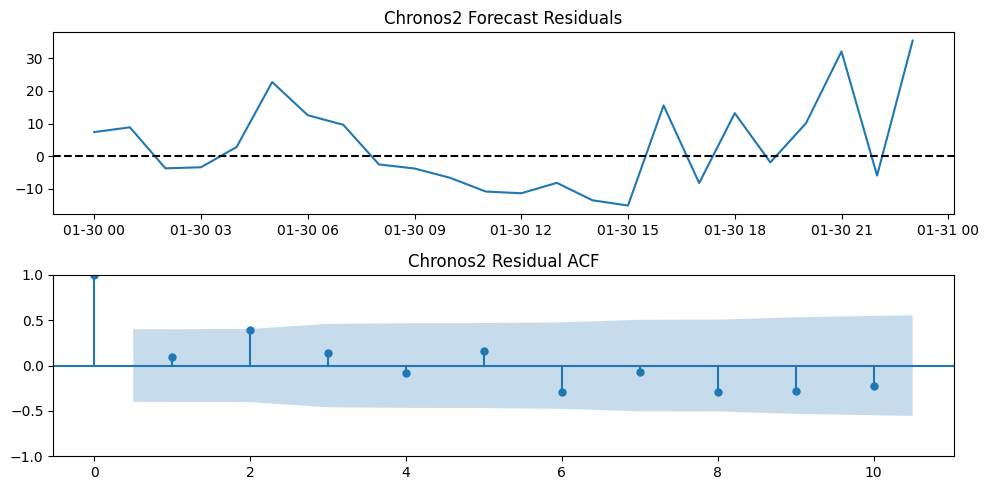

In [ ]:
# Chronos2 residual analysis — held-out 24 hours

chronos_residuals = y_test - chronos_pred

fig, axes = plt.subplots(2, 1, figsize=(10, 5))

axes[0].plot(test.index, chronos_residuals)
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set_title("Chronos2 Forecast Residuals")

plot_acf(chronos_residuals, lags=10, ax=axes[1])
axes[1].set_title("Chronos2 Residual ACF")

plt.tight_layout()
plt.show()

## E — Final Report


CyberPulse — Final Forecasting Report

1. Recommendation

Chronos2 is recommended for forecasting hourly network flow counts because it achieved lower forecasting errors than the Seasonal Naive baseline across five rolling backtesting windows.

2. Evidence

Model	MASE	Scaled CRPS (Approx.)	80% Coverage
Seasonal Naive	1.059	0.907	77.5%
Chronos2	0.717	0.575	62.5%

Chronos2 performed better on both point forecasting accuracy (MASE) and probabilistic forecast quality (approximate scaled CRPS). However, its prediction intervals were less reliable.

3. Prediction Intervals

Chronos2 produced narrower prediction intervals (average width: 32.64 flows) than Seasonal Naive (50.36 flows).

However, Chronos2 achieved only 62.5% coverage against the expected 80%, while Seasonal Naive achieved 77.5%.

This indicates that Chronos2 underestimated forecast uncertainty. Its intervals should not be considered well-calibrated.

4. Residual Analysis

Chronos2 residuals fluctuate around zero, with several large positive errors, particularly toward the end of the test period. Most residual ACF values remain within the confidence bounds, suggesting no strong remaining short-lag autocorrelation.

The model appears to underestimate some sudden increases in network flow counts. This suggests that irregular traffic spikes are not fully captured by the model.

5. Next Step

Calibrate Chronos2 prediction intervals using historical rolling backtesting errors to improve coverage toward the nominal 80%, without using future observations.

6. Limitations

The dataset is synthetic and covers approximately one month. Results should not be interpreted as evidence of real-world network attack detection.

The scaled CRPS values were approximated from nine forecast quantiles rather than calculated from a complete predictive distribution.
